# DeepLense Specific Test VI: super-resolution — data checks and baselines

**Task.** Make a 2× sharper image of a strong lens from a low-resolution (LR) image.
* **VI.A** — 10,000 simulated pairs, LR 75×75 → HR 150×150. Train a deep model, report **MSE, PSNR and SSIM** on a 90:10 split.
* **VI.B** — 300 real pairs, LR 64×64 (ground-based HSC survey) → HR 128×128 (Hubble). Too few to train from scratch well,
  so the idea is to start from the VI.A model and fine-tune it (few-shot / transfer learning).

**This notebook (CPU only, no training):** load and check both datasets, find out how the LR images relate to the HR images,
fix the train / validation / test split, and score simple baselines that any deep model must beat.

**Split.** 90 % train, 10 % test, as the task asks. 10 % of the train part is set aside as a **validation** set, used only to
choose models and settings (notebook 05). The test images are used only for the final numbers.

**Metrics.** Intensities are on a 0–1 scale, so PSNR = 10·log10(1 / MSE) with data range 1.0, and SSIM also uses data range 1.0.
Each metric is computed per image and then averaged.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.transform import resize

ROOT = Path("~/gsoc/eval-tests/ml4sci-deeplense").expanduser()
sys.path.insert(0, str(ROOT / "src"))
import deeplense_sr as S

FIG, REPORT = ROOT / "report/figures", ROOT / "report"
S.PROC.mkdir(parents=True, exist_ok=True)
SEED = 42

## 1. Load both datasets and check them

In [2]:
data = {}
for which in ["a", "b"]:
    LR, HR, names = S.load_pairs(which)       # checks inside: one-to-one LR/HR file pairing, 2x size, finite values
    data[which] = (LR, HR, names)
    print(f"VI.{which.upper()}: {len(names)} pairs | LR {LR.shape[1:]} | HR {HR.shape[1:]} | first files {names[:3]}")
    for nm, X in [("LR", LR), ("HR", HR)]:
        mn, mx = X.min(axis=(1, 2)), X.max(axis=(1, 2))
        print(f"   {nm}: min over images {mn.min():+.4f} .. {mn.max():+.4f} | max over images {mx.min():.4f} .. {mx.max():.4f} "
              f"| mean pixel {X.mean():.4f}")

VI.A: 10000 pairs | LR (75, 75) | HR (150, 150) | first files ['sample1.npy', 'sample2.npy', 'sample3.npy']
   LR: min over images -0.0016 .. +0.0059 | max over images 0.8803 .. 1.0406 | mean pixel 0.0615


   HR: min over images +0.0000 .. +0.0000 | max over images 1.0000 .. 1.0000 | mean pixel 0.0615
VI.B: 300 pairs | LR (64, 64) | HR (128, 128) | first files ['LR_1.npy', 'LR_2.npy', 'LR_3.npy']
   LR: min over images -0.0314 .. +0.0731 | max over images 0.9408 .. 1.0797 | mean pixel 0.1050
   HR: min over images -0.0477 .. +0.0190 | max over images 0.9049 .. 1.1094 | mean pixel 0.0340


## 2. Examples
Columns: LR input, bicubic upsampling of LR (the simplest method), the true HR image, and the absolute error of bicubic.

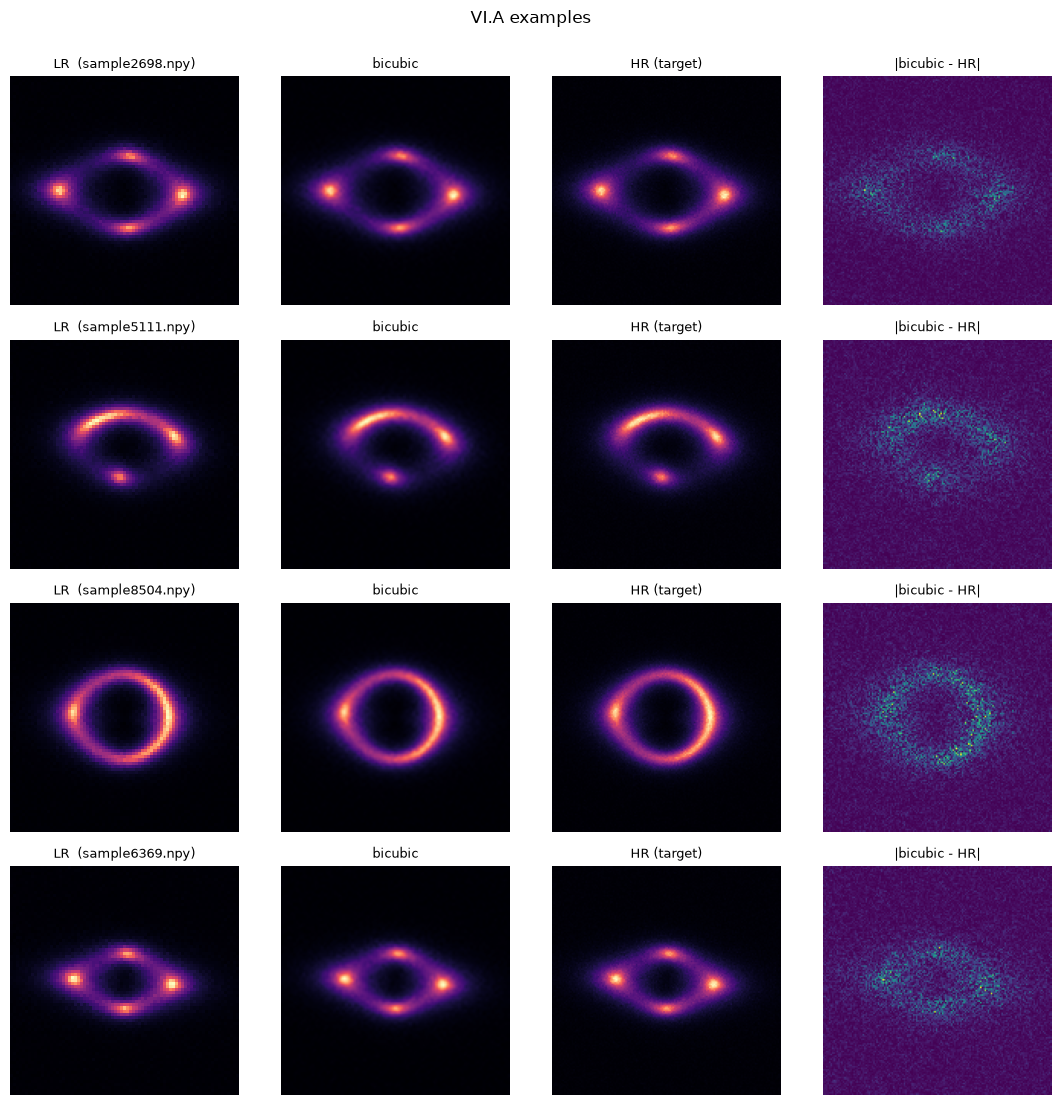

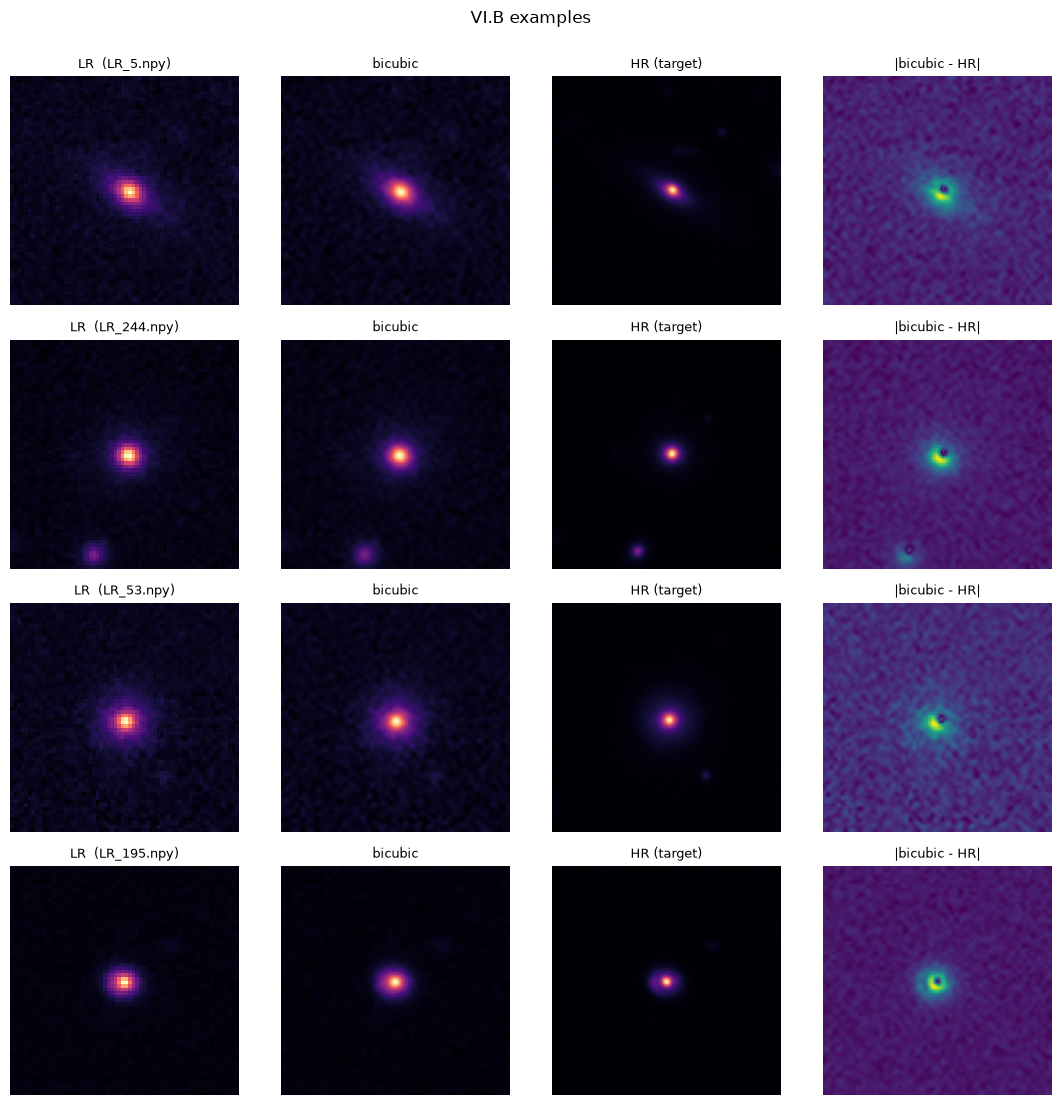

In [3]:
rng = np.random.default_rng(0)
for which in ["a", "b"]:
    LR, HR, names = data[which]
    pick = rng.choice(len(LR), 4, replace=False)
    BI = S.upsample_np(LR[pick])
    fig, axes = plt.subplots(4, 4, figsize=(11, 11))
    for r, i in enumerate(pick):
        for c, (img, title) in enumerate([(LR[i], "LR"), (BI[r], "bicubic"), (HR[i], "HR (target)"),
                                          (np.abs(BI[r] - HR[i]), "|bicubic - HR|")]):
            ax = axes[r, c]
            ax.imshow(img, cmap="magma" if c < 3 else "viridis", origin="lower")
            ax.set_title(f"{title}" + (f"  ({names[i]})" if c == 0 else ""), fontsize=9); ax.axis("off")
    fig.suptitle(f"VI.{which.upper()} examples", y=1.0)
    fig.tight_layout(); fig.savefig(FIG / f"04_examples_{which}.png", bbox_inches="tight"); plt.show()

## 3. How were the LR images made?
Knowing the degradation tells us what the model has to undo.

**VI.A.** Three guesses are compared on the first 200 pairs: averaging each 2×2 block of HR, anti-aliased bicubic shrinking,
and keeping every second pixel. The closest guess has the smallest difference to the real LR image; what remains is then
looked at as noise.

In [4]:
LR, HR, _ = data["a"]
n = 200
guess = {
    "2x2 block average": HR[:n].reshape(n, 75, 2, 75, 2).mean(axis=(2, 4)),
    "bicubic shrink (anti-aliased)": np.stack([resize(h, (75, 75), order=3, anti_aliasing=True) for h in HR[:n]]),
    "every second pixel": HR[:n, ::2, ::2],
}
rows = {}
for k, G in guess.items():
    res = LR[:n] - G
    rows[k] = {"RMS difference": np.sqrt((res ** 2).mean()), "mean difference": res.mean()}
display(pd.DataFrame(rows).T.round(5))

best_guess = min(rows, key=lambda k: rows[k]["RMS difference"])
res = LR[:n] - guess[best_guess]
nb_corr = np.corrcoef(res[:, :, :-1].ravel(), res[:, :, 1:].ravel())[0, 1]
bright = guess[best_guess] > 0.2
print(f"closest guess: {best_guess}")
print(f"residual after it: std {res.std():.5f} | correlation with right neighbour {nb_corr:+.3f} | "
      f"std on bright pixels {res[bright].std():.5f} vs dark {res[~bright].std():.5f}")

,RMS difference,mean difference
2x2 block average,0.00262,-0.0
bicubic shrink (anti-aliased),0.00207,0.0
every second pixel,0.01275,0.0


closest guess: bicubic shrink (anti-aliased)
residual after it: std 0.00207 | correlation with right neighbour -0.024 | std on bright pixels 0.00573 vs dark 0.00126


**VI.B.** These are two different telescopes, so the pairs are not made from each other. Two things are checked: the
brightness levels of LR and HR, and how well each bicubic-upsampled LR image matches its HR image (Pearson correlation).
A low correlation means a pair is badly aligned or the object looks different in the two surveys.

,LR,HR
mean pixel,0.1050,0.0340
mean of per-image median (background),0.0931,0.0261
mean of per-image max,0.9985,1.0169


correlation(bicubic LR, HR) per pair: quantiles {'min': np.float64(0.015), '5%': np.float64(0.577), '25%': np.float64(0.785), '50%': np.float64(0.879), '75%': np.float64(0.929), 'max': np.float64(0.989)}
pairs with correlation < 0.5: 9 of 300


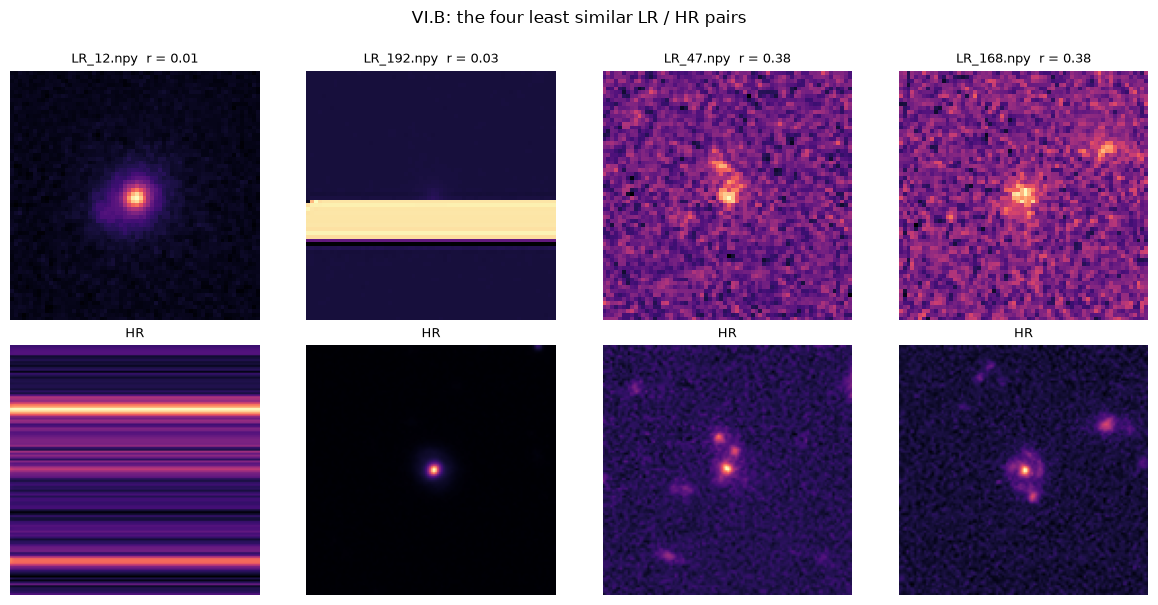

In [5]:
LR, HR, names = data["b"]
BI = S.upsample_np(LR)
corr = np.array([np.corrcoef(b.ravel(), h.ravel())[0, 1] for b, h in zip(BI, HR)])
stats = pd.DataFrame({
    "LR": [LR.mean(), np.median(LR, axis=(1, 2)).mean(), LR.max(axis=(1, 2)).mean()],
    "HR": [HR.mean(), np.median(HR, axis=(1, 2)).mean(), HR.max(axis=(1, 2)).mean()]},
    index=["mean pixel", "mean of per-image median (background)", "mean of per-image max"]).round(4)
display(stats)
print("correlation(bicubic LR, HR) per pair: quantiles",
      dict(zip(["min", "5%", "25%", "50%", "75%", "max"], np.round(np.quantile(corr, [0, .05, .25, .5, .75, 1]), 3))))
print("pairs with correlation < 0.5:", int((corr < 0.5).sum()), "of", len(corr))

worst = np.argsort(corr)[:4]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for c, i in enumerate(worst):
    axes[0, c].imshow(LR[i], cmap="magma", origin="lower"); axes[0, c].set_title(f"{names[i]}  r = {corr[i]:.2f}", fontsize=9)
    axes[1, c].imshow(HR[i], cmap="magma", origin="lower"); axes[1, c].set_title("HR", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
fig.suptitle("VI.B: the four least similar LR / HR pairs", y=1.0)
fig.tight_layout(); fig.savefig(FIG / "04_b_worst_pairs.png", bbox_inches="tight"); plt.show()

## 4. Train / validation / test split (fixed, saved)
Random permutation with seed 42. Test = 10 %; validation = 10 % of the rest; train = the remainder. All of these pairs are
independent images, so a random split does not leak information. Low-similarity VI.B pairs are **kept** in every set: dropping
them would make the test numbers look better than they are.

In [6]:
splits = {}
for which in ["a", "b"]:
    names = data[which][2]
    sp = S.make_split(len(names), SEED)
    assert not (set(sp["train"]) & set(sp["valid"]) or set(sp["train"]) & set(sp["test"]) or set(sp["valid"]) & set(sp["test"]))
    assert len(sp["train"]) + len(sp["valid"]) + len(sp["test"]) == len(names)
    splits[which] = sp
    (S.PROC / f"split_{which}.json").write_text(json.dumps(
        {"seed": SEED, **{k: v.tolist() for k, v in sp.items()}, "files": {k: [names[i] for i in v] for k, v in sp.items()}}))
    print(f"VI.{which.upper()}: train {len(sp['train'])} | valid {len(sp['valid'])} | test {len(sp['test'])}")
reloaded = S.load_split("b")
assert all((reloaded[k] == splits["b"][k]).all() for k in reloaded)

VI.A: train 8100 | valid 900 | test 1000
VI.B: train 243 | valid 27 | test 30


## 5. Baselines (no learning)
* **nearest**: each LR pixel is copied into a 2×2 block.
* **bicubic**: smooth cubic interpolation, the standard reference in super-resolution papers.
* **bicubic + brightness fit** (VI.B only): HR and LR come from different telescopes with different background levels, so a
  single linear mapping `a · bicubic + b` is fitted on the **train** pairs (least squares) and applied to validation and test.
  This removes the brightness mismatch; a deep model has to do better than this to show it recovers real detail.

Validation numbers are shown next to the test numbers. Nothing here is tuned, so the test set is not used for any choice.

In [7]:
def nearest(LR):
    return LR.repeat(2, axis=1).repeat(2, axis=2)

rows, per_image = [], {}
for which in ["a", "b"]:
    LR, HR, _ = data[which]
    sp = splits[which]
    methods = {"nearest": nearest, "bicubic": S.upsample_np}
    if which == "b":
        bt = S.upsample_np(LR[sp["train"]]).ravel()
        ht = HR[sp["train"]].ravel().astype(np.float64)
        a_ = np.cov(bt, ht)[0, 1] / bt.var(ddof=1)          # least-squares slope and intercept
        b_ = ht.mean() - a_ * bt.mean()
        print(f"VI.B brightness fit on train pairs: HR ≈ {a_:.4f} · bicubic(LR) {b_:+.4f}")
        methods["bicubic + brightness fit"] = lambda X, a_=a_, b_=b_: a_ * S.upsample_np(X) + b_
    for part in ["valid", "test"]:
        idx = sp[part]
        for name, f in methods.items():
            m = S.metrics(f(LR[idx]), HR[idx])
            per_image[(which, part, name)] = m
            rows.append({"dataset": f"VI.{which.upper()}", "set": part, "method": name, "n": len(idx),
                         **S.summarise(m).to_dict(), "PSNR std": m.psnr.std()})
base = pd.DataFrame(rows).set_index(["dataset", "set", "method"])
display(base.round({"MSE": 6, "PSNR (dB)": 2, "SSIM": 4, "PSNR std": 2}))

_ = (REPORT / "results_04_baselines.json").write_text(json.dumps(
    {"baselines": {" | ".join(k): v for k, v in base.to_dict("index").items()},
     "vib_brightness_fit": {"a": float(a_), "b": float(b_)}}, indent=2, default=float))

VI.B brightness fit on train pairs: HR ≈ 0.4381 · bicubic(LR) -0.0116


n       MSE  PSNR (dB)    SSIM  \
dataset set   method                                                        
VI.A    valid nearest                    900  0.000162      38.02  0.9696   
              bicubic                    900  0.000070      41.61  0.9747   
        test  nearest                   1000  0.000161      38.07  0.9696   
              bicubic                   1000  0.000069      41.62  0.9747   
VI.B    valid nearest                     27  0.009867      23.10  0.4041   
              bicubic                     27  0.009765      23.17  0.4152   
              bicubic + brightness fit    27  0.001504      30.45  0.6635   
        test  nearest                     30  0.018027      20.19  0.2935   
              bicubic                     30  0.017874      20.25  0.3058   
              bicubic + brightness fit    30  0.002473      29.11  0.6704   

                                        PSNR std  
dataset set   method                              
VI.A    valid nearest                       1.04  
              bicubic                       0.59  
        test  nearest                       1.05  
              bicubic                       0.58  
VI.B    valid nearest                       5.16  
              bicubic                       5.19  
              bicubic + brightness fit      4.24  
        test  nearest                       4.87  
              bicubic                       4.90  
              bicubic + brightness fit      4.55

## 6. Notes

**Data checks.** VI.A has 10,000 pairs (LR 75×75, HR 150×150) and VI.B has 300 pairs (LR 64×64, HR 128×128). Every LR file has
exactly one HR partner, and all values are finite. VI.A HR images are min-max scaled per image to exactly 0–1; their LR images
go slightly below 0 and above 1, which is consistent with added noise. VI.B images are near 0–1 but not exactly
(about −0.05 to 1.11), so outputs are never clipped and PSNR / SSIM use a fixed data range of 1.0.

**How VI.A LR images were made.** An anti-aliased bicubic shrink of HR reproduces LR best (RMS difference 0.0021, against
0.0026 for 2×2 averaging and 0.0128 for dropping every second pixel). The remainder is almost uncorrelated between neighbouring
pixels (−0.02) and about 4.5× larger on bright pixels than on dark ones (std 0.0057 vs 0.0013). That is what Poisson-like
(signal-dependent) noise looks like. So the model must undo blur **and** suppress noise, and LR and HR have the same mean brightness.

**VI.B is a different problem.** The LR images are ground-based (HSC) and the HR images are from Hubble, so they differ in more
than resolution. The LR background is about 3.6× brighter (median 0.093 vs 0.026). Most pairs match well after bicubic upsampling
(median correlation 0.88), but 9 of 300 pairs have correlation below 0.5 and the worst is 0.015. Those pairs are kept in all
sets so that the test numbers stay honest.

**Split.** Seed 42: VI.A 8,100 train / 900 valid / 1,000 test; VI.B 243 / 27 / 30. Saved to `data/processed/superres/split_{a,b}.json`.

**Baselines (test set).**

| | MSE | PSNR (dB) | SSIM |
|---|---|---|---|
| VI.A nearest | 1.61e-4 | 38.07 | 0.9696 |
| VI.A bicubic | 6.9e-5 | 41.62 | 0.9747 |
| VI.B nearest | 1.80e-2 | 20.19 | 0.2935 |
| VI.B bicubic | 1.79e-2 | 20.25 | 0.3058 |
| VI.B bicubic + brightness fit | 2.47e-3 | 29.11 | 0.6704 |

On VI.A, bicubic is already strong (41.6 dB), because the images are smooth and mostly dark sky. A deep model has to earn
every tenth of a dB. On VI.B, a single linear brightness mapping fitted on train pairs (HR ≈ 0.438 · bicubic − 0.012) gains
almost 9 dB. This means most of the plain-bicubic error on VI.B is brightness mismatch, not missing detail. Notebook 05 therefore
compares deep models against the brightness-fit baseline, not against plain bicubic. With only 30 VI.B test pairs, the PSNR
standard deviation across images is about 4.5 dB, so differences on VI.B need a confidence interval.